## Importing libraries

In [64]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## data preprocessing

### Training image preprocessing

In [65]:
training_set = tf.keras.utils.image_dataset_from_directory(
    'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation='bilinear'
)

Found 70295 files belonging to 38 classes.


## validation image preprocessing

In [66]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation='bilinear'
)

Found 17572 files belonging to 38 classes.


In [67]:
training_set

<BatchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

## Building model

In [68]:
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Input, Flatten,Dropout
from tensorflow.keras.models import Sequential

In [69]:
model = Sequential()

### building Convolution layer

In [70]:
model.add(Input(shape=(128, 128, 3)))
model.add(Conv2D(filters=32, kernel_size=3, padding="same", activation="relu"))
model.add(Conv2D(filters=32, kernel_size=3, activation="relu"))
model.add(MaxPool2D(pool_size=2, strides=2))


In [71]:

model.add(Conv2D(filters=64, kernel_size=3, padding="same", activation="relu"))
model.add(Conv2D(filters=64, kernel_size=3, activation="relu"))
model.add(MaxPool2D(pool_size=2, strides=2))


In [72]:

model.add(Conv2D(filters=128, kernel_size=3, padding="same", activation="relu"))
model.add(Conv2D(filters=128, kernel_size=3, activation="relu"))
model.add(MaxPool2D(pool_size=2, strides=2))


In [73]:

model.add(Conv2D(filters=256, kernel_size=3, padding="same", activation="relu"))
model.add(Conv2D(filters=256, kernel_size=3, activation="relu"))
model.add(MaxPool2D(pool_size=2, strides=2))


In [74]:

model.add(Conv2D(filters=512, kernel_size=3, padding="same", activation="relu"))
model.add(Conv2D(filters=512, kernel_size=3, activation="relu"))
model.add(MaxPool2D(pool_size=2, strides=2))


In [75]:
model.add(Dropout(0.25))

In [76]:
model.add(Flatten())

In [77]:
model.add(Dense(units=1500,activation='relu'))

In [78]:
model.add(Dropout(0.4))

#### output layer

In [79]:
model.add(Dense(units=38,activation='softmax'))

## compiling model

In [80]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate =0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [81]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_28 (Conv2D)          (None, 128, 128, 32)      896       
                                                                 
 conv2d_29 (Conv2D)          (None, 126, 126, 32)      9248      
                                                                 
 max_pooling2d_13 (MaxPoolin  (None, 63, 63, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_30 (Conv2D)          (None, 63, 63, 64)        18496     
                                                                 
 conv2d_31 (Conv2D)          (None, 61, 61, 64)        36928     
                                                                 
 max_pooling2d_14 (MaxPoolin  (None, 30, 30, 64)       0         
 g2D)                                                 

## model training

In [82]:
training_history = model.fit(
    x=training_set,
    validation_data=validation_set,
    epochs=10
)

Epoch 1/10
2197/2197 [==============================] - 170s 76ms/step - loss: 1.3982 - accuracy: 0.5904 - val_loss: 0.5902 - val_accuracy: 0.8125
Epoch 2/10
2197/2197 [==============================] - 167s 76ms/step - loss: 0.4664 - accuracy: 0.8519 - val_loss: 0.3049 - val_accuracy: 0.9002
Epoch 3/10
2197/2197 [==============================] - 166s 76ms/step - loss: 0.2729 - accuracy: 0.9120 - val_loss: 0.1844 - val_accuracy: 0.9404
Epoch 4/10
2197/2197 [==============================] - 175s 80ms/step - loss: 0.1914 - accuracy: 0.9380 - val_loss: 0.1661 - val_accuracy: 0.9472
Epoch 5/10
2197/2197 [==============================] - 170s 77ms/step - loss: 0.1377 - accuracy: 0.9552 - val_loss: 0.1494 - val_accuracy: 0.9529
Epoch 6/10
2197/2197 [==============================] - 187s 85ms/step - loss: 0.1096 - accuracy: 0.9635 - val_loss: 0.1095 - val_accuracy: 0.9641
Epoch 7/10
2197/2197 [==============================] - 207s 94ms/step - loss: 0.0859 - accuracy: 0.9716 - val_loss: 0

## Model Evaluation

In [83]:
# model evaluation onn training set
train_loss,train_acc = model.evaluate(training_set)

2197/2197 [==============================] - 64s 29ms/step - loss: 0.0455 - accuracy: 0.9851


In [84]:
print(train_loss,train_acc)

0.04553509131073952 0.9851198792457581


In [85]:
valid_loss,valid_acc = model.evaluate(validation_set)

550/550 [==============================] - 16s 28ms/step - loss: 0.1439 - accuracy: 0.9573


In [86]:
print(valid_loss,valid_acc)

0.14387597143650055 0.9573184847831726


## Saving Model

In [87]:
model.save("trained_model.h5")

In [88]:
training_history.history

{'loss': [1.398231029510498,
  0.46636030077934265,
  0.2728893756866455,
  0.19142122566699982,
  0.1376681923866272,
  0.10958240926265717,
  0.08594301342964172,
  0.0761152133345604,
  0.06409844756126404,
  0.055742256343364716],
 'accuracy': [0.5903691649436951,
  0.8518528938293457,
  0.912027895450592,
  0.9380468130111694,
  0.95516037940979,
  0.9635393619537354,
  0.9716053605079651,
  0.9745074510574341,
  0.9792304039001465,
  0.981961727142334],
 'val_loss': [0.5902140736579895,
  0.30490565299987793,
  0.18437615036964417,
  0.16611680388450623,
  0.14937056601047516,
  0.10946767032146454,
  0.12867052853107452,
  0.14840680360794067,
  0.10044679045677185,
  0.1438758373260498],
 'val_accuracy': [0.8124857544898987,
  0.9001821279525757,
  0.9404165744781494,
  0.9472455978393555,
  0.9528796076774597,
  0.9641475081443787,
  0.9602777361869812,
  0.9545299410820007,
  0.9710903763771057,
  0.9573184847831726]}

In [89]:
#record history
import json
with open("training history",'w') as f:
    json.dump(training_history.history,f)

## Accuracy visuailzation

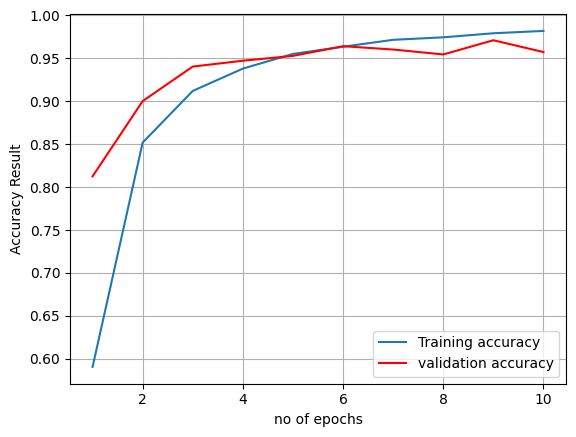

In [90]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],label='Training accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],label='validation accuracy',color='red')
plt.xlabel("no of epochs")
plt.ylabel("Accuracy Result")
plt.legend()
plt.grid()
plt.show()

## mertrics for model evaluation

In [91]:
class_name = validation_set.class_names
class_name

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [92]:
test_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=False,
    interpolation='bilinear'
)

Found 17572 files belonging to 38 classes.


In [93]:
y_pred = model.predict(test_set)
y_pred, y_pred.shape

550/550 [==============================] - 14s 26ms/step


(array([[9.99985337e-01, 1.22001074e-06, 1.52440685e-10, ...,
         7.62422487e-15, 6.93949996e-15, 9.54375671e-14],
        [9.99955058e-01, 2.17933066e-05, 1.70501878e-07, ...,
         1.81359597e-14, 1.59391583e-10, 7.60738477e-13],
        [9.99942422e-01, 5.42781127e-05, 2.28346356e-10, ...,
         3.63470139e-15, 3.46257555e-13, 8.65145032e-13],
        ...,
        [1.98174099e-08, 1.05187754e-10, 1.46396914e-07, ...,
         1.30752200e-08, 9.56283830e-10, 9.99945521e-01],
        [5.98247363e-09, 7.38279316e-12, 2.65494062e-08, ...,
         1.57512297e-08, 9.75677317e-10, 9.99968767e-01],
        [6.99591329e-10, 1.18161911e-10, 6.78645806e-09, ...,
         4.47336568e-09, 2.14183586e-07, 9.79624033e-01]], dtype=float32),
 (17572, 38))

In [94]:
predicted_catrgories = tf.argmax(y_pred,axis=1)

In [95]:
predicted_catrgories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [96]:
true_catrgories = tf.concat([ y for x,y in test_set], axis=0)
true_catrgories

<tf.Tensor: shape=(17572, 38), dtype=float32, numpy=
array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]], dtype=float32)>

In [97]:
y_true = tf.argmax(true_catrgories,axis=1)
y_true

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [98]:
from sklearn.metrics import classification_report

In [99]:
print(classification_report(y_true,predicted_catrgories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.97      0.93      0.95       504
                                 Apple___Black_rot       0.99      0.97      0.98       497
                          Apple___Cedar_apple_rust       0.99      0.98      0.98       440
                                   Apple___healthy       0.98      0.87      0.92       502
                               Blueberry___healthy       0.93      0.97      0.95       454
          Cherry_(including_sour)___Powdery_mildew       0.97      0.98      0.97       421
                 Cherry_(including_sour)___healthy       0.99      0.95      0.97       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.94      0.88      0.91       410
                       Corn_(maize)___Common_rust_       1.00      0.99      1.00       477
               Corn_(maize)___Northern_Leaf_Blight       0.89      0.97      0.

In [ ]:
import json
from sklearn.metrics import classification_report

# Generate report dictionary
report_dict = classification_report(
    y_true,
    predicted_catrgories,
    target_names=class_name,
    output_dict=True
)

# Save to JSON
with open('classification_report.json', 'w') as f:
    json.dump(report_dict, f, indent=4)

print("Saved classification_report.json successfully!")